<a href="https://colab.research.google.com/github/HONGSAHUN/AI-Class/blob/main/Week06_1012/abalone_1012.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 전복 딥러닝 분류 + 회귀

In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_squared_log_error
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold

In [43]:
df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/abalone.csv")

In [44]:
from sklearn.model_selection import train_test_split

# df 데이터를 8:2로 나누기
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

# df_train과 df_test를 확인
print("Training data size:", df_train.shape)
print("Test data size:", df_test.shape)


Training data size: (3341, 10)
Test data size: (836, 10)


In [45]:
df_train.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
4038,4038,I,0.550,0.445,0.125,0.6720,0.2880,0.1365,0.210,11
1272,1272,I,0.475,0.355,0.100,0.5035,0.2535,0.0910,0.140,8
3384,3384,F,0.305,0.225,0.070,0.1485,0.0585,0.0335,0.045,7
3160,3160,I,0.275,0.200,0.065,0.1165,0.0565,0.0130,0.035,7
3894,3894,M,0.495,0.380,0.135,0.6295,0.2630,0.1425,0.215,12


In [46]:
print(df_train.info())

<class 'pandas.core.frame.DataFrame'>
Index: 3341 entries, 4038 to 860
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              3341 non-null   int64  
 1   Sex             3341 non-null   object 
 2   Length          3341 non-null   float64
 3   Diameter        3341 non-null   float64
 4   Height          3341 non-null   float64
 5   Whole_weight    3341 non-null   float64
 6   Shucked_weight  3341 non-null   float64
 7   Viscera_weight  3341 non-null   float64
 8   Shell_weight    3341 non-null   float64
 9   Rings           3341 non-null   int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 287.1+ KB
None


Shucked_weight =  Whole weight.1
Viscera_weight =  Whole weight.2

In [47]:
df_train.describe()

,id,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
count,3341.000000,3341.000000,3341.000000,3341.000000,3341.000000,3341.000000,3341.000000,3341.000000,3341.000000
mean,2116.754565,0.524964,0.408518,0.139790,0.830838,0.360561,0.180832,0.239682,9.944627
std,1202.682792,0.119137,0.098687,0.042514,0.491583,0.223018,0.109444,0.139941,3.207344
min,0.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,1078.000000,0.450000,0.350000,0.115000,0.443000,0.186500,0.093000,0.130000,8.000000
50%,2121.000000,0.545000,0.425000,0.140000,0.802000,0.337000,0.171000,0.234000,9.000000
75%,3163.000000,0.615000,0.480000,0.165000,1.151000,0.503500,0.253500,0.328500,11.000000
max,4175.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [48]:
def plot_numerics(data):
    numeric_columns = data.columns
    for column in numeric_columns:
        _, ax = plt.subplots(1,2, figsize=(16, 5))
        ax=ax.flatten()

        # Histogram
        sns.histplot(data[column], bins=50, kde=True, color='skyblue', ax=ax[0])
        ax[0].set_title(f'Histogram of {column}', fontsize=15,fontweight='bold')
        ax[0].set_xlabel(column, fontsize=12)
        ax[0].set_ylabel('Frequency', fontsize=12)

        # Box plot
        sns.boxplot(x=data[column], color='lightgreen', ax=ax[1])
        ax[1].set_title(f'Box plot of {column}', fontsize=15,fontweight='bold')
        ax[1].set_xlabel(column, fontsize=12)

        plt.tight_layout()
        plt.show()

def get_count_plot(cat):
    ax=sns.countplot(x=df_train[cat],
                   order=df_train[cat].value_counts(ascending=False).index);

    abs_values = df_train[cat].value_counts(ascending=False)
    rel_values = df_train[cat].value_counts(ascending=False, normalize=True).values * 100
    lbls = [f'{p[0]} ({p[1]:.0f}%)' for p in zip(abs_values, rel_values)]

    ax.bar_label(container=ax.containers[0], labels=lbls)
    ax.set_title("Distribution of "+cat+" Values",fontsize=16)

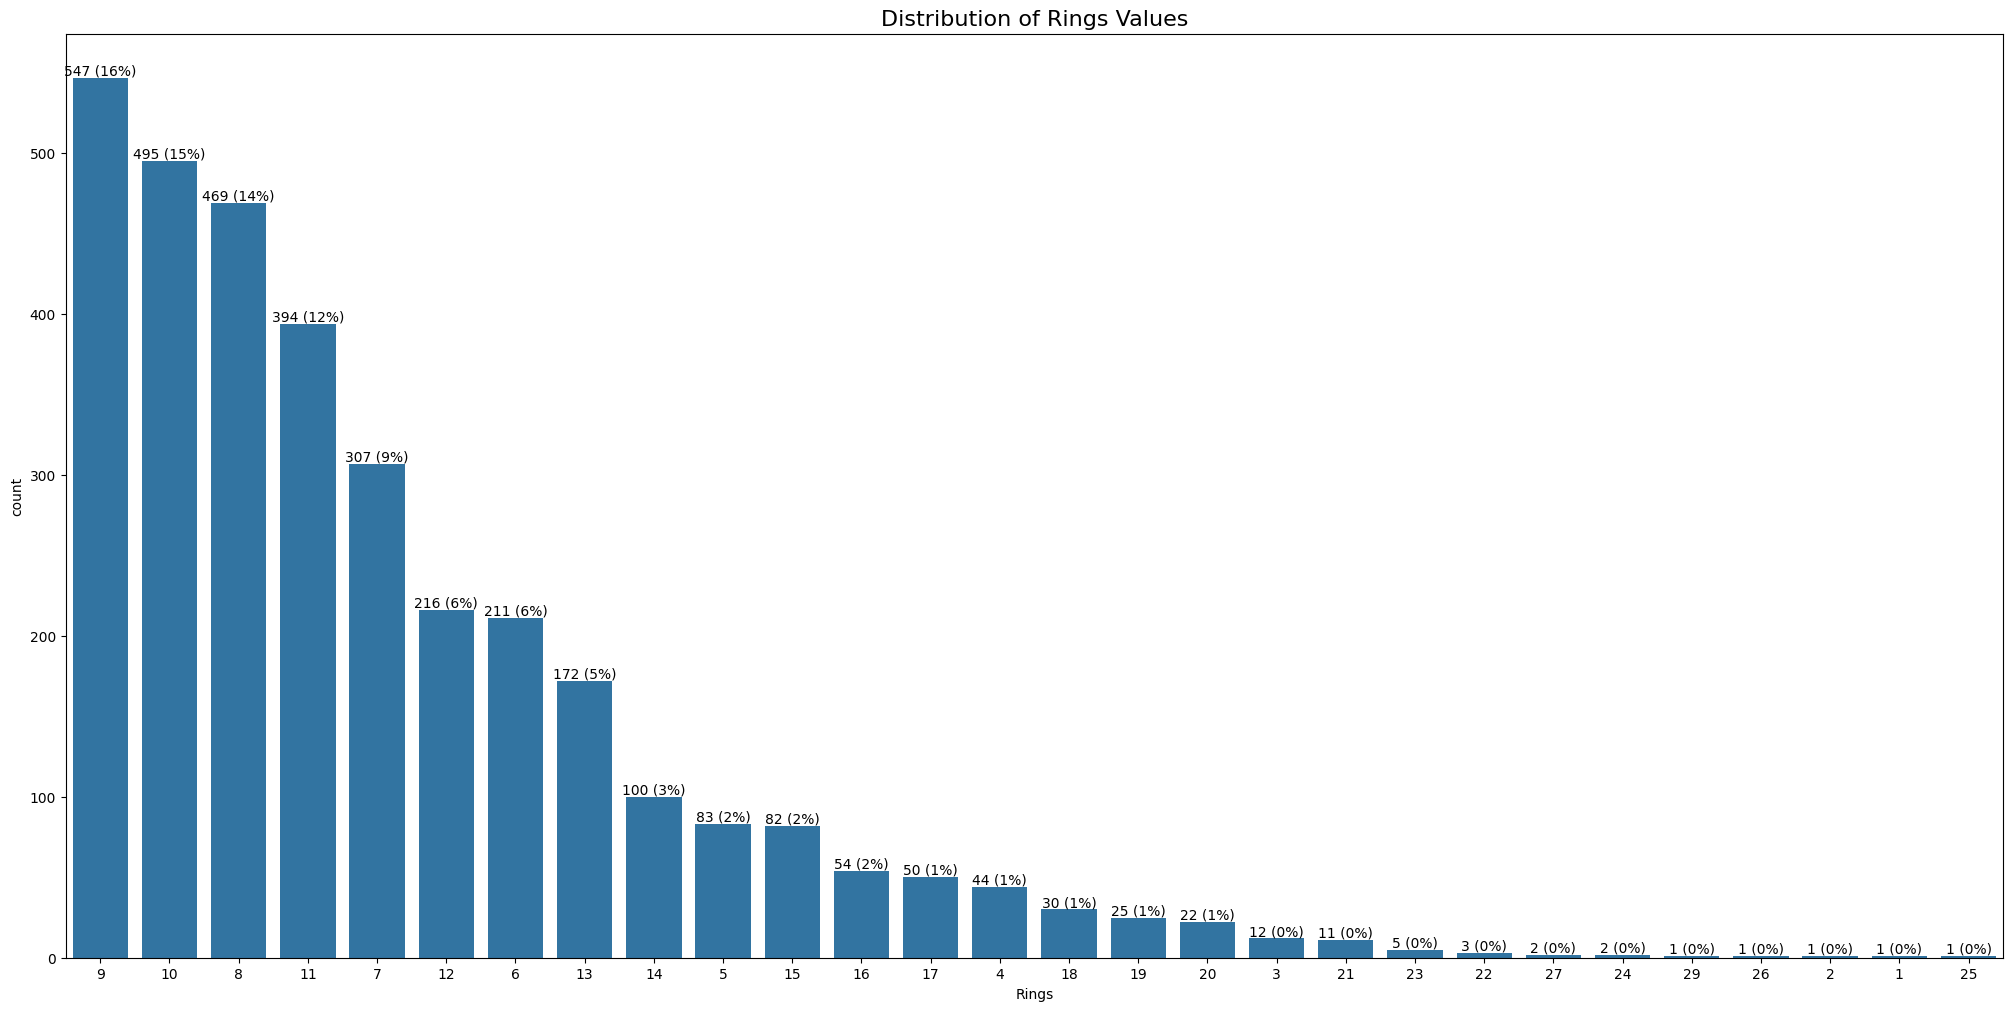

In [49]:
plt.figure(figsize=(25, 12))
get_count_plot('Rings')

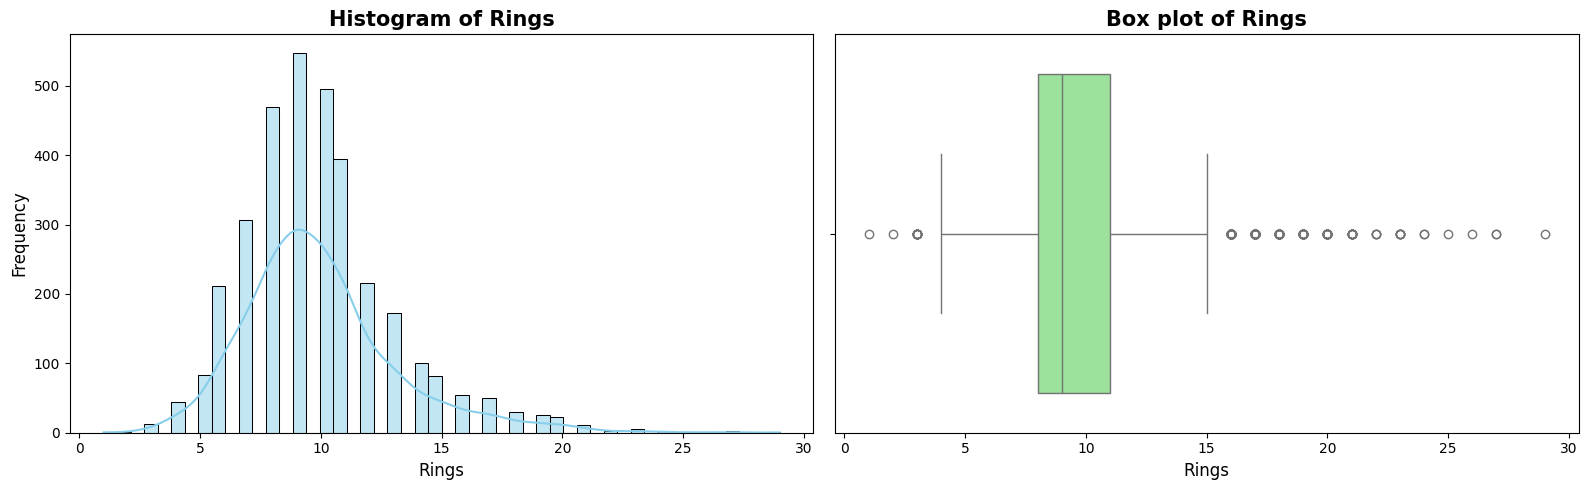

In [50]:
plot_numerics(df_train[['Rings']])


In [51]:
df_train.columns

Index(['id', 'Sex', 'Length', 'Diameter', 'Height', 'Whole_weight',
       'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings'],
      dtype='object')

In [52]:
df_train["Whole weight Ratio"] = df_train["Shucked_weight"] / df_train["Whole_weight"]

In [53]:
df_train

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Whole weight Ratio
4038,4038,I,0.550,0.445,0.125,0.6720,0.2880,0.1365,0.210,11,0.428571
1272,1272,I,0.475,0.355,0.100,0.5035,0.2535,0.0910,0.140,8,0.503476
3384,3384,F,0.305,0.225,0.070,0.1485,0.0585,0.0335,0.045,7,0.393939
3160,3160,I,0.275,0.200,0.065,0.1165,0.0565,0.0130,0.035,7,0.484979
3894,3894,M,0.495,0.380,0.135,0.6295,0.2630,0.1425,0.215,12,0.417792
...,...,...,...,...,...,...,...,...,...,...,...
3444,3444,F,0.490,0.400,0.115,0.5690,0.2560,0.1325,0.145,9,0.449912
466,466,F,0.670,0.550,0.190,1.3905,0.5425,0.3035,0.400,12,0.390147
3092,3092,M,0.510,0.395,0.125,0.5805,0.2440,0.1335,0.188,11,0.420327
3772,3772,M,0.575,0.465,0.120,1.0535,0.5160,0.2185,0.235,9,0.489796


In [54]:
cat_cols=['Sex']
num_cols=['Length', 'Diameter', 'Height',
             'Whole_weight','Shucked_weight',
             'Viscera_weight', 'Shell_weight', "Whole weight Ratio"]

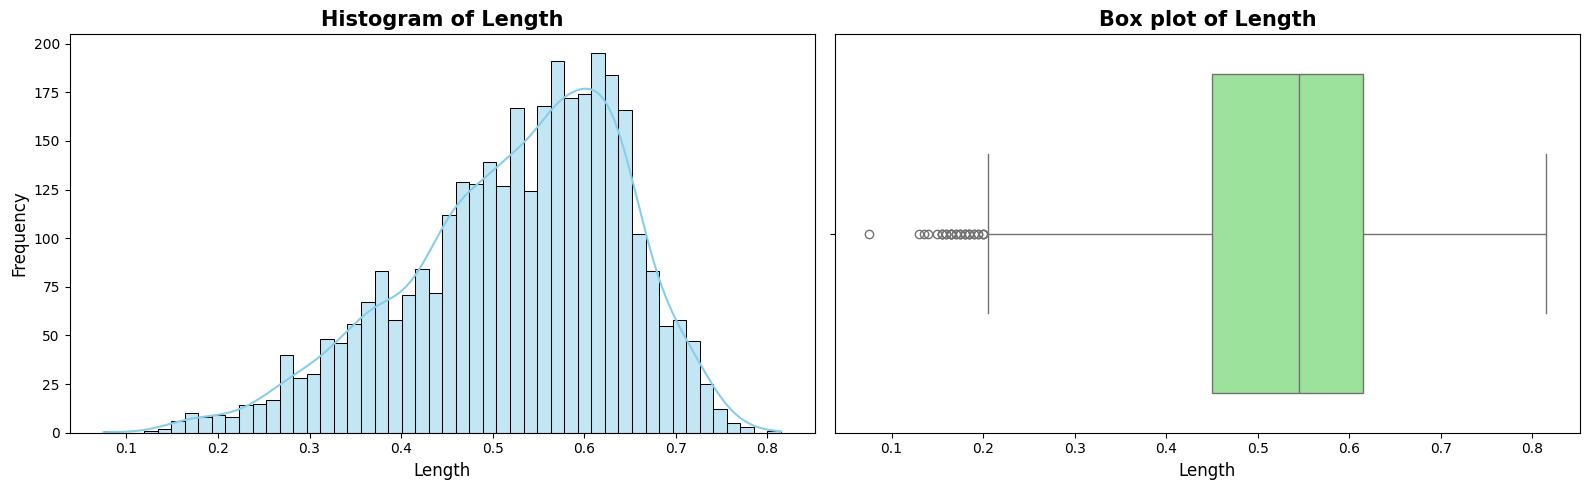

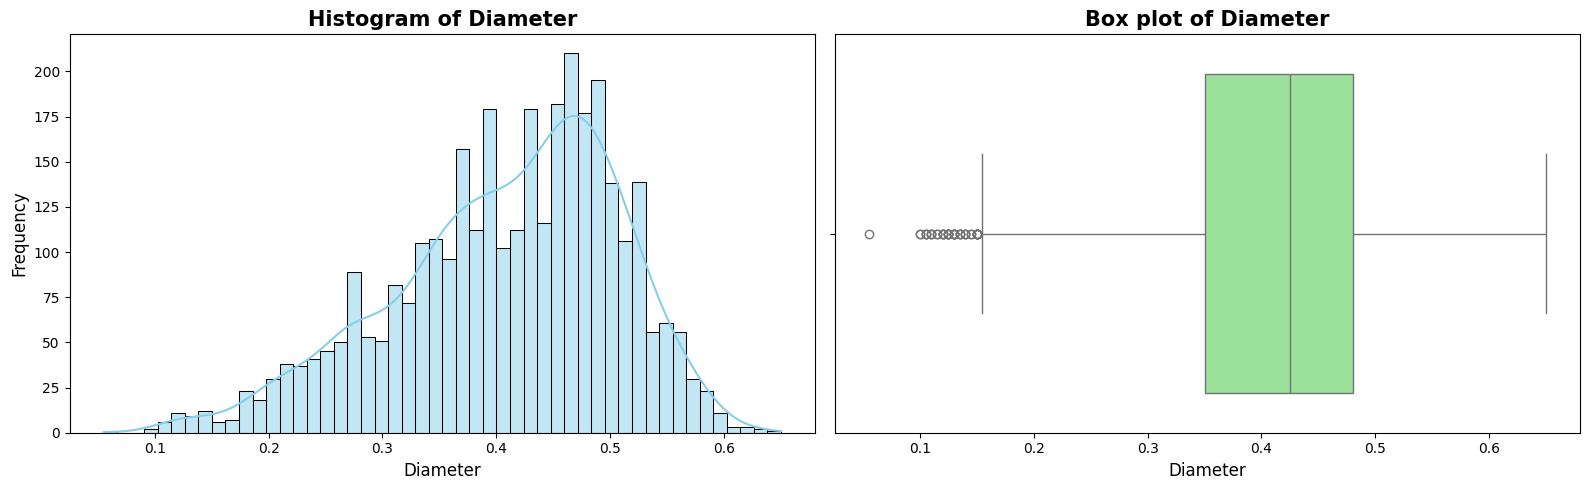

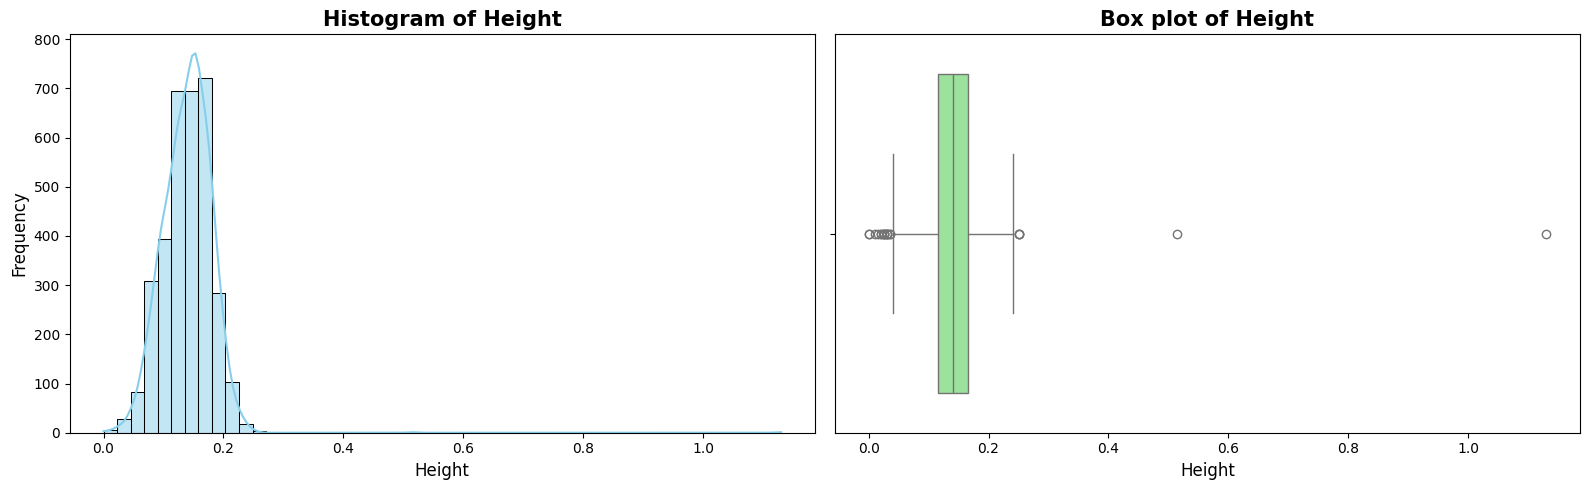

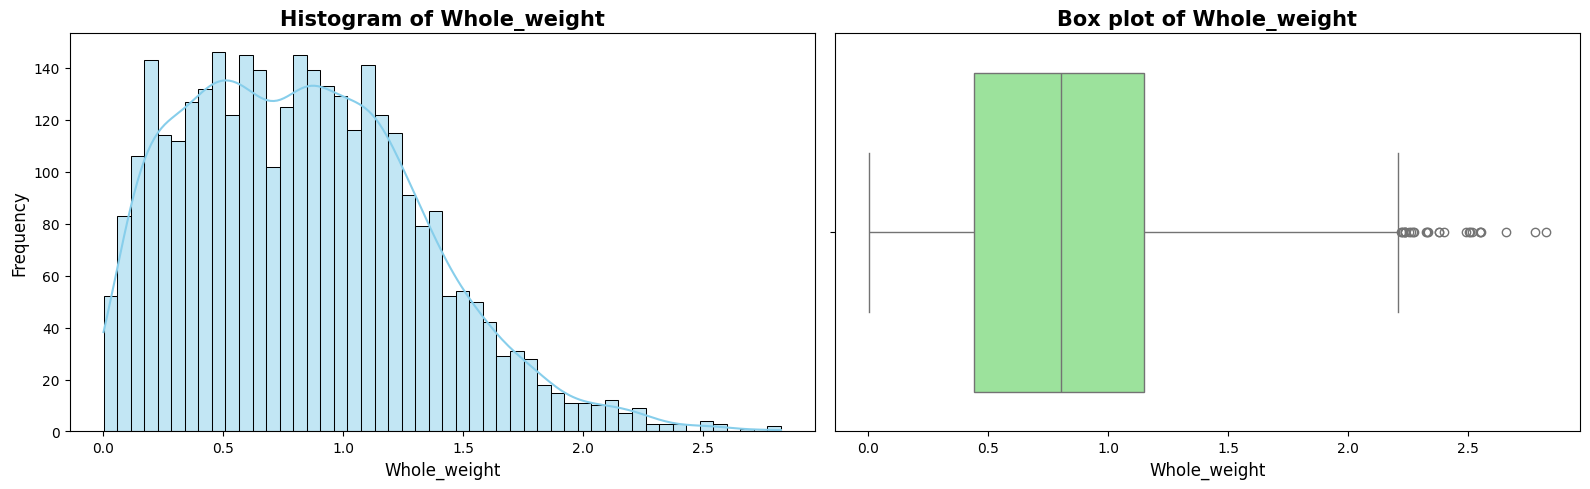

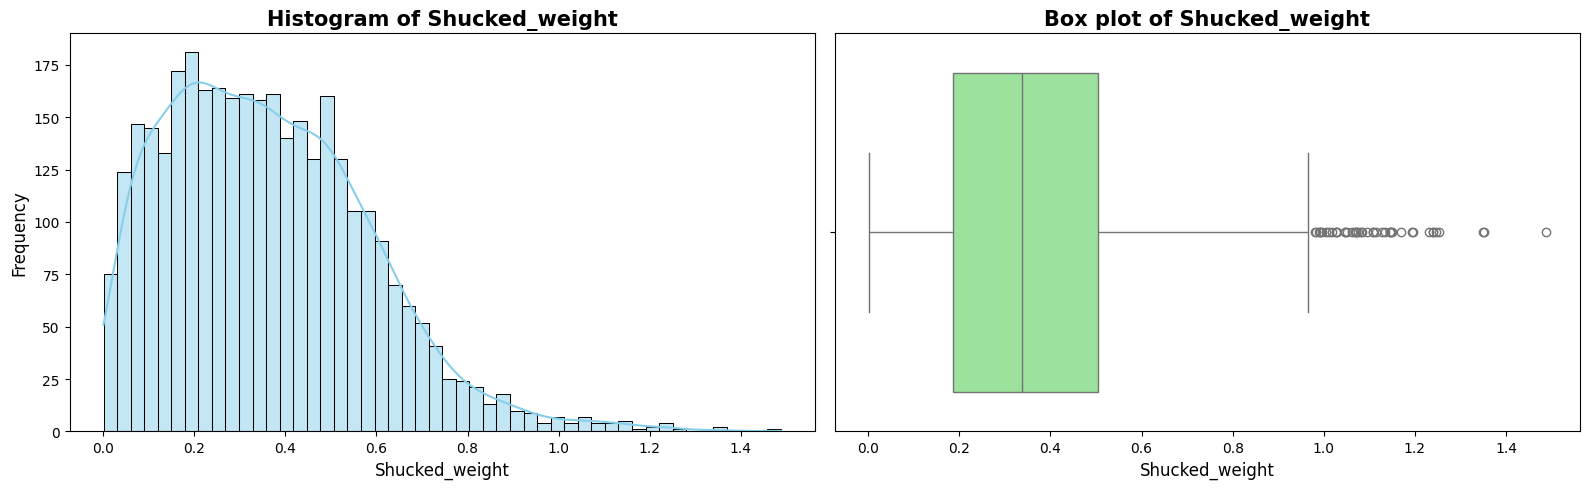

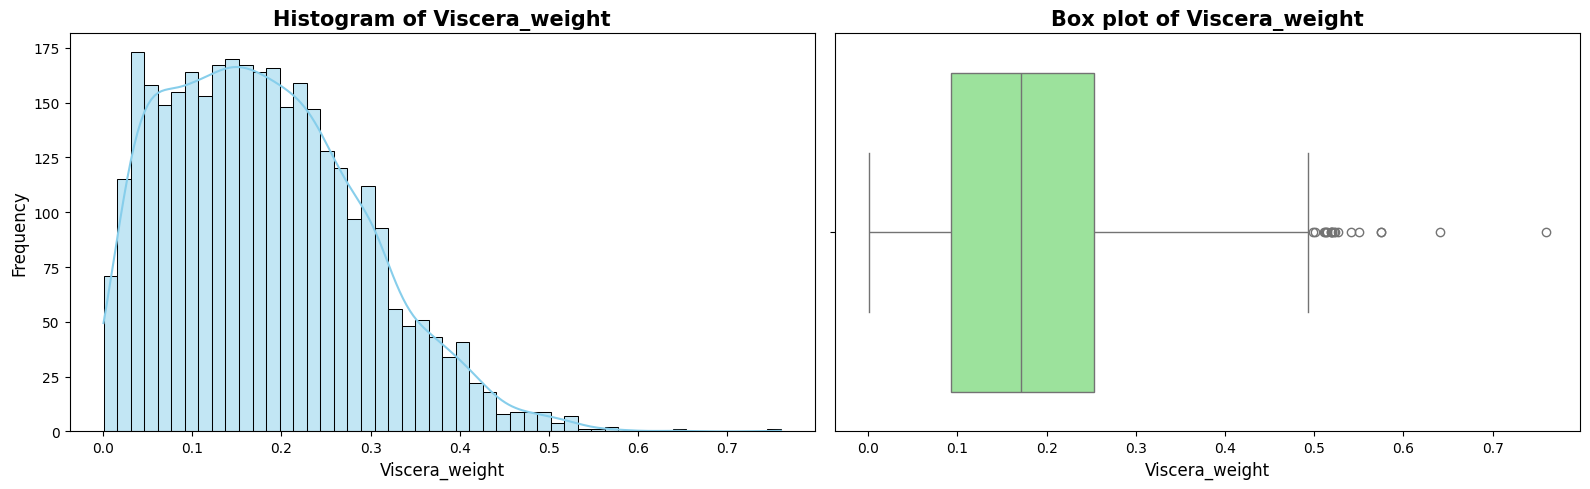

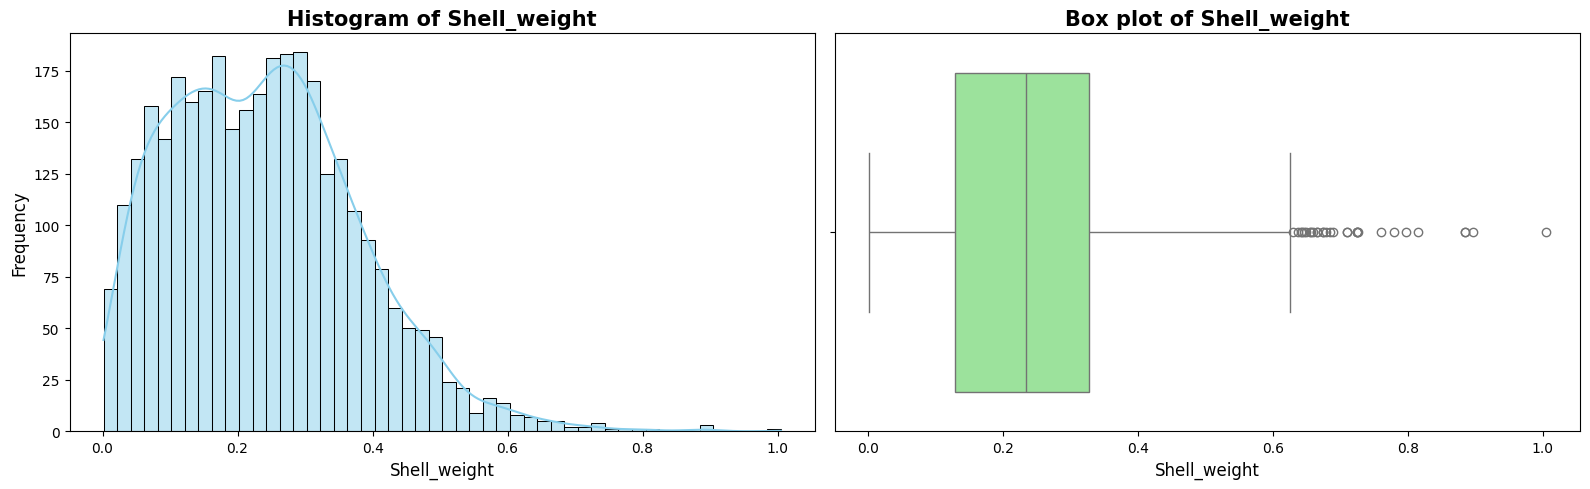

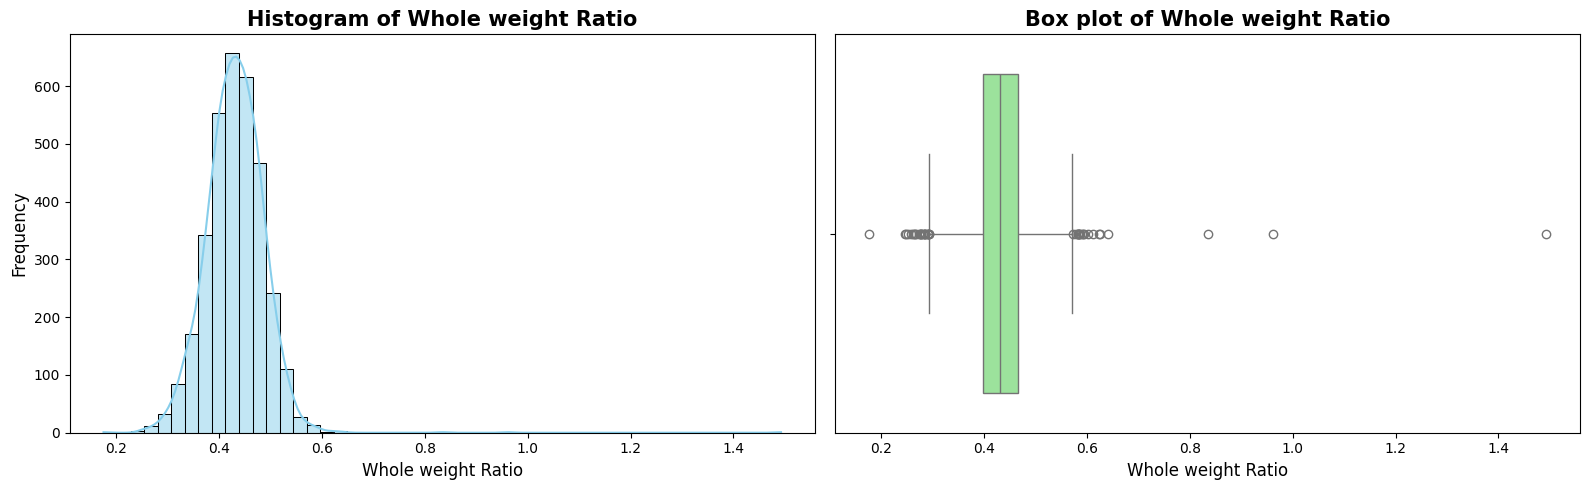

In [55]:
plot_numerics(df_train[num_cols])

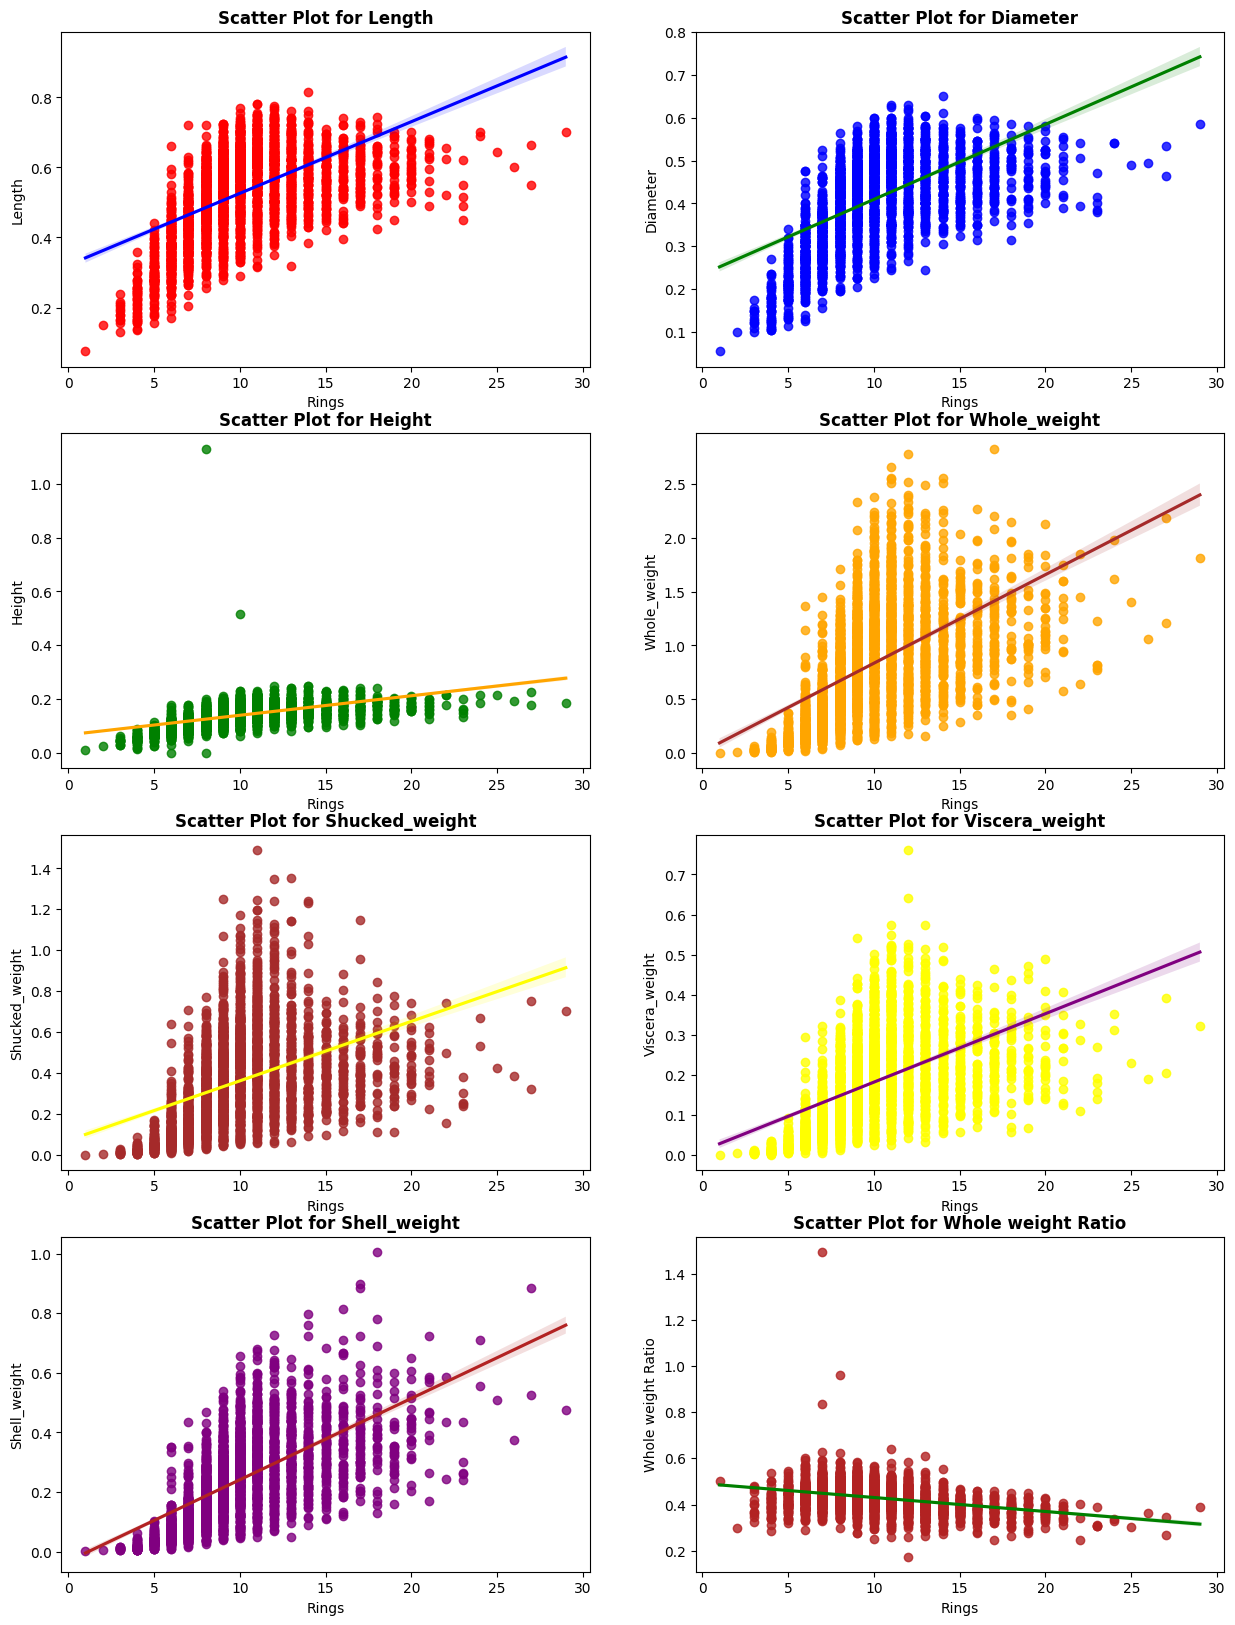

In [56]:
n_cols = 2
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axs = axs.flatten() if n_rows > 1 else [axs]

colors=['red','blue','green','orange','brown','yellow','purple','firebrick','green']
for i, ncol in enumerate(num_cols):
    sns.regplot(data=df_train, x="Rings", y=ncol, ax=axs[i],
                color=colors[i],line_kws=dict(color=colors[i+1]))
    axs[i].set_title(f'Scatter Plot for {ncol}',fontweight='bold')


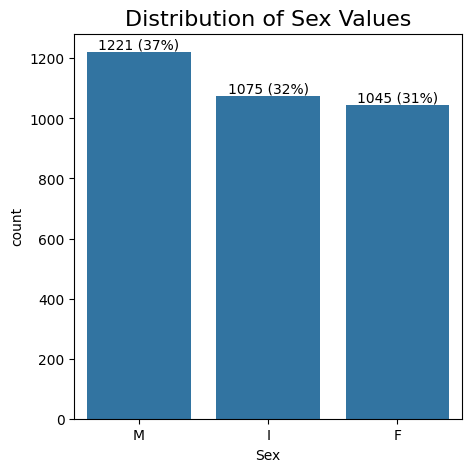

In [57]:
plt.figure(figsize=(5, 5))
get_count_plot('Sex')

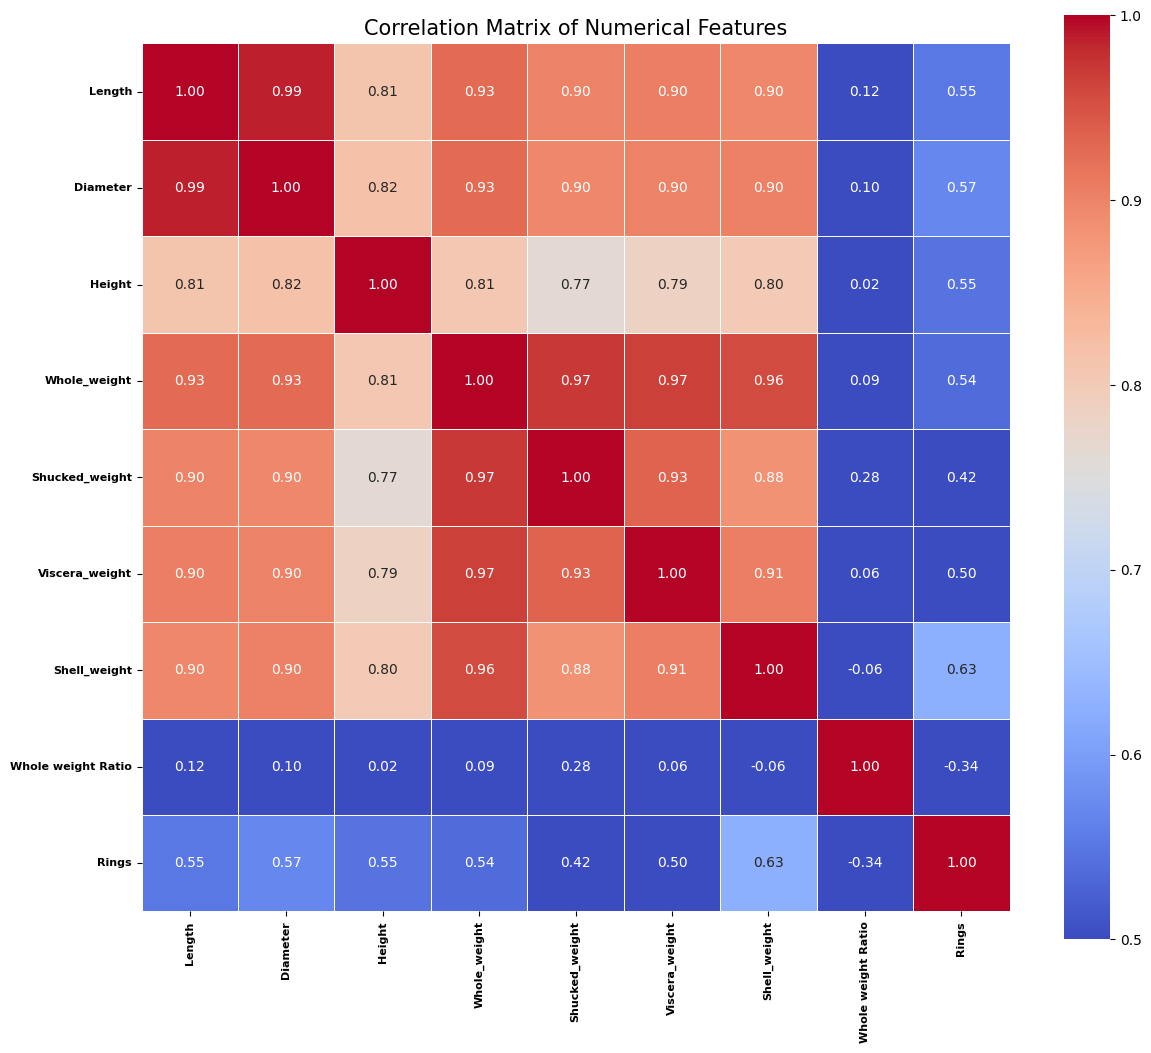

In [58]:
corr_matrix = df_train[num_cols+['Rings']].corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, vmax=1, vmin=0.5, center=0.75,annot=True, fmt=".2f", square=True,
            linewidths=.5, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features', fontsize=15)
plt.xticks(fontsize=8,fontweight='bold')
plt.yticks(fontsize=8,fontweight='bold')
plt.show()

In [59]:
num_cols=['Length','Diameter','Height',"Whole weight Ratio"]

In [60]:
def getFeats(df):

    df["Whole weight Ratio"]=df["Shucked_weight"]/df["Whole_weight"]
    df["Shell_weight"]=np.log(0.00001+df["Shell_weight"])
    df["Whole_weight"]=np.log(0.00001+df["Whole_weight"])
    df["Shucked_weight"]=np.log(0.00001+df["Shucked_weight"])
    df["Viscera_weight"]=np.log(0.00001+df["Viscera_weight"])

    sex_dict={'I':0,'M':1,'F':2}
    df['Sex']=df['Sex'].map(sex_dict)

    scaler = StandardScaler()
    df[num_cols] = scaler.fit_transform(df[num_cols])

    return df

In [61]:
df_train['typ']=0
df_test['typ']=1
#
df_all=pd.concat([df_train,df_test],axis=0)
df_all=getFeats(df_all)
df_all.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings,Whole weight Ratio,typ
4038,4038,0,0.216591,0.374075,-0.347099,-0.397482,-1.244760,-1.991357,-1.560600,11,-0.036338,0
1272,1272,0,-0.408000,-0.532927,-0.944870,-0.686152,-1.372352,-2.396786,-1.966041,8,0.671962,0
3384,3384,2,-1.823741,-1.843041,-1.662195,-1.907103,-2.838558,-3.395911,-3.100871,7,-0.363821,0
3160,3160,0,-2.073577,-2.094986,-1.781749,-2.149778,-2.873338,-4.342037,-3.352122,7,0.497052,0
3894,3894,1,-0.241443,-0.280982,-0.107991,-0.462814,-1.335563,-1.948343,-1.537071,12,-0.138270,0


In [62]:
df_all['Rings'].value_counts()

,count
Rings,
9,689
10,634
8,568
11,487
7,391
12,267
6,259
13,203
14,126


In [63]:
from sklearn.preprocessing import LabelEncoder

# LabelEncoder를 사용하여 숫자로 인코딩
label_encoder = LabelEncoder()
df_all['Rings'] = label_encoder.fit_transform(df_all['Rings'])

In [64]:
df_all['Rings'].value_counts()

,count
Rings,
8,689
9,634
7,568
10,487
6,391
11,267
5,259
12,203
13,126


In [65]:
# 필요한 라이브러리 임포트
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

# 데이터 준비
df_train = df_all[df_all['typ'] == 0]
df_test = df_all[df_all['typ'] == 1]

# 피처와 타겟 설정
X_train = df_train.drop(['id', 'Rings', 'typ'], axis=1)
y_train = df_train['Rings']
X_test = df_test.drop(['id', 'Rings', 'typ'], axis=1)
y_test = df_test['Rings']

# 훈련과 검증 데이터로 분리
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)



In [66]:
# RandomForestClassifier 모델 생성
rf = RandomForestClassifier(random_state=42)

# 하이퍼파라미터 그리드 설정
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
}
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid,
                           scoring='accuracy', cv=3, verbose=2, n_jobs=-1)

# 모델 학습
grid_search.fit(X_train, y_train)

# 최적 하이퍼파라미터 출력
print(f"Best Hyperparameters: {grid_search.best_params_}")


Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Hyperparameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 200}


In [67]:

# 최적의 모델로 테스트 데이터 예측
y_pred = grid_search.predict(X_test)

# 정확도 평가
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy * 100:.2f}%')

# 추가 평가 지표 출력 (classification report)
print(classification_report(y_test, y_pred))


Accuracy: 25.12%
              precision    recall  f1-score   support

           2       0.25      0.33      0.29         3
           3       0.33      0.38      0.36        13
           4       0.44      0.38      0.41        32
           5       0.29      0.25      0.27        48
           6       0.38      0.35      0.36        84
           7       0.33      0.43      0.38        99
           8       0.25      0.27      0.26       142
           9       0.23      0.27      0.25       139
          10       0.21      0.20      0.21        93
          11       0.12      0.08      0.09        51
          12       0.06      0.13      0.09        31
          13       0.22      0.08      0.11        26
          14       0.08      0.05      0.06        21
          15       0.10      0.08      0.09        13
          16       0.17      0.12      0.14         8
          17       0.00      0.00      0.00        12
          18       0.00      0.00      0.00         7
          

# 딥러닝 준비

In [68]:
import tensorflow as tf
from sklearn.metrics import confusion_matrix, mean_absolute_error, r2_score

print(X_train.columns.tolist())
print(X_train.shape, X_val.shape, X_test.shape)

dl_scaler = StandardScaler()
Xtr = dl_scaler.fit_transform(X_train.values)
Xva = dl_scaler.transform(X_val.values)
Xte = dl_scaler.transform(X_test.values)
n_features = Xtr.shape[1]

['Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Whole weight Ratio']
(2672, 9) (669, 9) (836, 9)


## 딥러닝 분류 — Rings를 클래스로

In [69]:
num_classes = len(label_encoder.classes_)
print("클래스 수:", num_classes)

ytr_oh = tf.keras.utils.to_categorical(y_train.values, num_classes)
yva_oh = tf.keras.utils.to_categorical(y_val.values, num_classes)
yte_oh = tf.keras.utils.to_categorical(y_test.values, num_classes)
print(ytr_oh.shape)

클래스 수: 28
(2672, 28)


In [70]:
cls_model = tf.keras.Sequential([
    tf.keras.Input(shape=(n_features,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])
cls_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cls_model.summary()

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = cls_model.fit(Xtr, ytr_oh, epochs=300, batch_size=32,
                        validation_data=(Xva, yva_oh), callbacks=[es], verbose=0)
print("학습한 epoch 수:", len(history.history['loss']))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 28)             │           924 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,644 (14.23 KB)

 Trainable params: 3,644 (14.23 KB)

 Non-trainable params: 0 (0.00 B)

학습한 epoch 수: 34


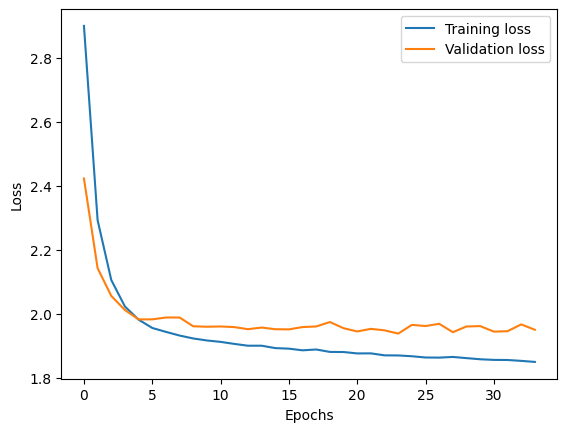

In [71]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.show()

In [72]:
y_test_class = np.argmax(yte_oh, axis=1)
y_pred_class = np.argmax(cls_model.predict(Xte), axis=1)

print("DL Accuracy:", accuracy_score(y_test_class, y_pred_class))
print(classification_report(y_test_class, y_pred_class, zero_division=0))

print("실제 :", label_encoder.inverse_transform(y_test_class[:10]))
print("예측 :", label_encoder.inverse_transform(y_pred_class[:10]))

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
DL Accuracy: 0.2822966507177033
              precision    recall  f1-score   support

           2       0.00      0.00      0.00         3
           3       0.50      0.54      0.52        13
           4       0.52      0.38      0.44        32
           5       0.43      0.50      0.46        48
           6       0.34      0.42      0.37        84
           7       0.47      0.26      0.34        99
           8       0.27      0.48      0.35       142
           9       0.16      0.03      0.05       139
          10       0.23      0.54      0.32        93
          11       0.14      0.02      0.03        51
          12       0.11      0.23      0.15        31
          13       0.00      0.00      0.00        26
          14       0.00      0.00      0.00        21
          15       0.25      0.08      0.12        13
          16       0.33      0.12      0.18         8
          17       0.00      0.00      0.00        12
          

## 딥러닝 회귀 — Rings를 숫자로

In [73]:
ytr_r = label_encoder.inverse_transform(y_train.values).astype('float32')
yva_r = label_encoder.inverse_transform(y_val.values).astype('float32')
yte_r = label_encoder.inverse_transform(y_test.values).astype('float32')
print(ytr_r[:10])

[ 9. 10. 15. 10. 10.  7.  5. 11.  7.  9.]


In [74]:
reg_model = tf.keras.Sequential([
    tf.keras.Input(shape=(n_features,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])
reg_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history = reg_model.fit(Xtr, ytr_r, epochs=300, batch_size=32,
                        validation_data=(Xva, yva_r), callbacks=[es], verbose=0)
print("학습한 epoch 수:", len(history.history['loss']))

학습한 epoch 수: 105


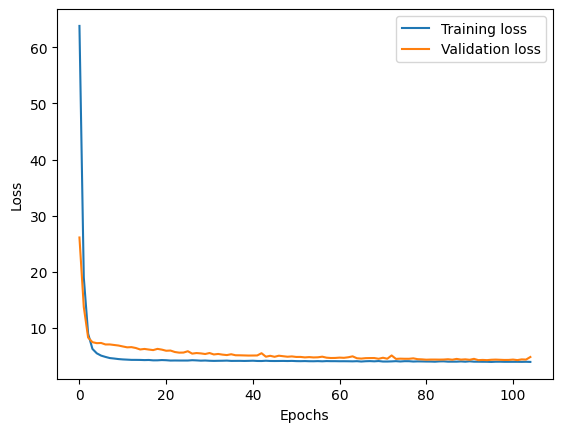

In [75]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.show()

In [76]:
y_pred_r = reg_model.predict(Xte).flatten()
mse = mean_squared_error(yte_r, y_pred_r)
print("MSE :", mse)
print("RMSE:", mse ** 0.5)
print("MAE :", mean_absolute_error(yte_r, y_pred_r))
print("R2  :", r2_score(yte_r, y_pred_r))
print("Baseline RMSE (평균으로 찍기):", mean_squared_error(yte_r, np.full_like(yte_r, ytr_r.mean())) ** 0.5)

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
MSE : 5.412664890289307
RMSE: 2.326513462305625
MAE : 1.5262819528579712
R2  : 0.4999944567680359
Baseline RMSE (평균으로 찍기): 3.2915749999855364


## 나이대 3그룹 분류

In [77]:
def to_group(rings):
    return pd.cut(rings, bins=[0, 8, 10, 30], labels=False)

gtr, gva, gte = to_group(ytr_r), to_group(yva_r), to_group(yte_r)
print(pd.Series(gtr).value_counts().sort_index())

g_model = tf.keras.Sequential([
    tf.keras.Input(shape=(n_features,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
g_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
g_model.fit(Xtr, gtr, epochs=300, batch_size=32, validation_data=(Xva, gva), callbacks=[es], verbose=0)

g_pred = np.argmax(g_model.predict(Xte), axis=1)
print("Accuracy:", accuracy_score(gte, g_pred))
print(confusion_matrix(gte, g_pred))
print(classification_report(gte, g_pred, target_names=['young(<=8)', 'mid(9-10)', 'old(>=11)']))

0    901
1    823
2    948
Name: count, dtype: int64
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Accuracy: 0.6543062200956937
[[218  48  13]
 [ 51 136  94]
 [ 13  70 193]]
              precision    recall  f1-score   support

  young(<=8)       0.77      0.78      0.78       279
   mid(9-10)       0.54      0.48      0.51       281
   old(>=11)       0.64      0.70      0.67       276

    accuracy                           0.65       836
   macro avg       0.65      0.65      0.65       836
weighted avg       0.65      0.65      0.65       836

